# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score


url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"

df = pd.read_csv(url)

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The dataset includes a variety of information about hotel bookings, such as lead time, number of guests, cancellations, and room prices. One thing that stands out is that some columns, like agent and company, may have missing values. There are also both numerical and categorical columns, which means we will need to clean and prepare the data before clustering.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [12]:
features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]
df_cluster = df[features].copy()

df_cluster.head()

df_cluster = df_cluster.drop_duplicates()
for col in features:
    df_cluster[col] = pd.to_numeric(
        df_cluster[col], errors='coerce'
    )
for col in features:
    Q1 = df_cluster[col].quantile(0.25)
    Q3 = df_cluster[col].quantile(0.75)
    IQR = Q3 - Q1

    if IQR > 0:
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df_cluster = df_cluster[
            (df_cluster[col] >= lower) &
            (df_cluster[col] <= upper)
        ]
print("Shape after cleaning:", df_cluster.shape)

print(df_cluster.isnull().sum())

df_cluster = df_cluster.dropna()

print("Shape after dropping missing values:", df_cluster.shape)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_cluster)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_cluster.index
)

X_scaled.head()



Shape after cleaning: (6014, 5)
lead_time                    0
stays_in_weekend_nights      0
stays_in_week_nights         0
adr                          0
total_of_special_requests    0
dtype: int64
Shape after dropping missing values: (6014, 5)


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
2,-0.875579,-1.147894,-0.993758,-0.378397,-0.897807
3,-0.766687,-1.147894,-0.993758,-0.378397,-0.897807
4,-0.748538,-1.147894,-0.548053,0.050526,0.462589
6,-1.002619,-1.147894,-0.548053,0.218366,-0.897807
7,-0.839281,-1.147894,-0.548053,0.143771,0.462589


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead time, weekend nights, weekday nights, average daily rate, and total special requests. I chose these features because they help explain customer booking behavior, including how early guests book, how long they stay, how much they pay, and whether they have special requests.

2. I expect to find different groups of customers, such as those who book far in advance, those who book last minute, and those who stay for longer periods. I also think we might find customers who spend more per night or make more special requests compared to others.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

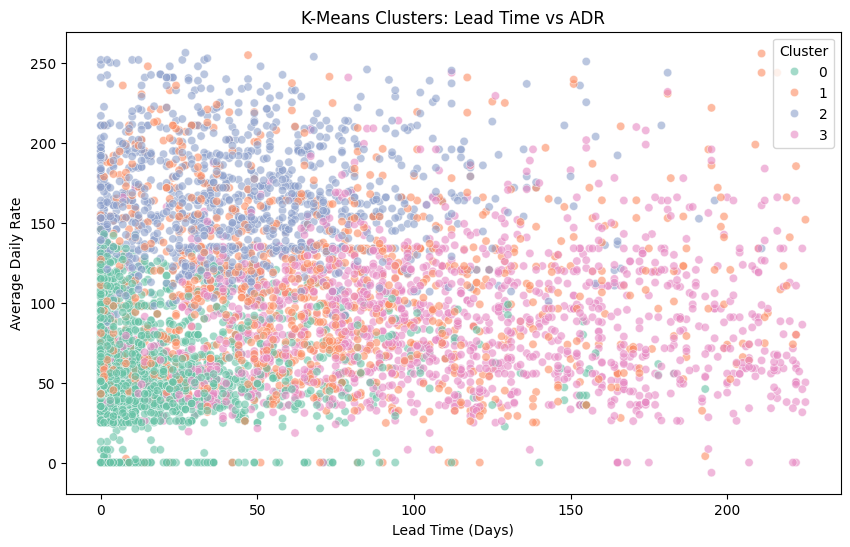

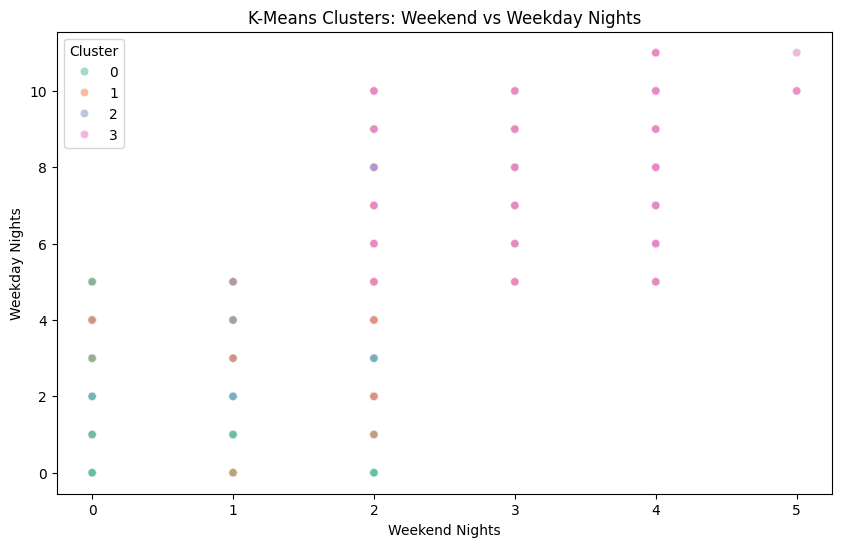

,count
cluster,
0,2131
1,1184
2,1197
3,1502


In [13]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df_cluster['cluster'] = kmeans.fit_predict(X_scaled)

df_cluster.head()
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x='lead_time',
    y='adr',
    hue='cluster',
    palette='Set2',
    alpha=0.6
)

plt.title('K-Means Clusters: Lead Time vs ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate')
plt.legend(title='Cluster')
plt.show()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x='stays_in_weekend_nights',
    y='stays_in_week_nights',
    hue='cluster',
    palette='Set2',
    alpha=0.6
)

plt.title('K-Means Clusters: Weekend vs Weekday Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Weekday Nights')
plt.legend(title='Cluster')
plt.show()

cluster_summary = df_cluster.groupby('cluster')[features].mean()

cluster_summary = cluster_summary.round(2)

cluster_summary


df_cluster['cluster'].value_counts().sort_index()



### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose a k value of 4 because I wanted to divide the customers into four different groups based on their booking behavior. Four clusters seemed like a reasonable starting point because it allows us to identify different customer types without creating too many groups.

2. Based on the features selected, the clusters can help identify customers with different booking habits. Some clusters may represent customers who book far in advance, while others may include customers who book closer to their arrival date. Other groups might include customers who stay longer, pay higher room rates, or make more special requests. The most important variables for each cluster will depend on which averages stand out in the cluster summary table.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

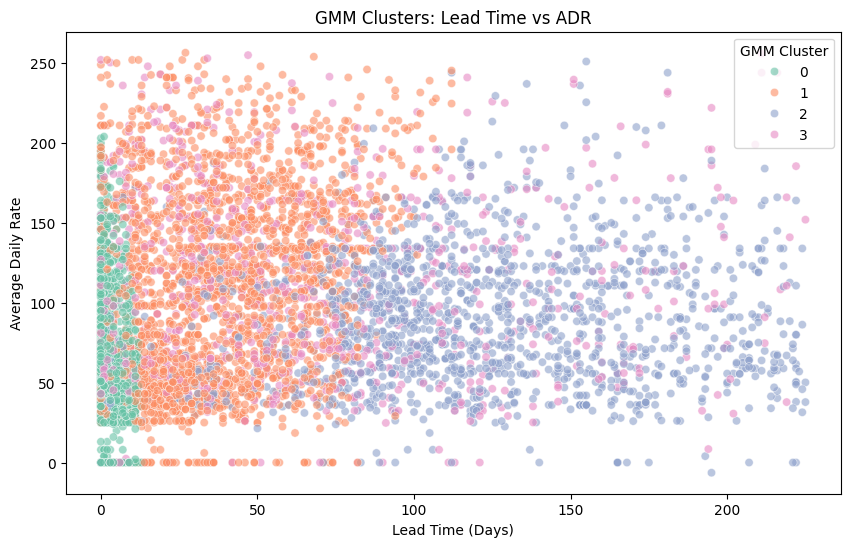

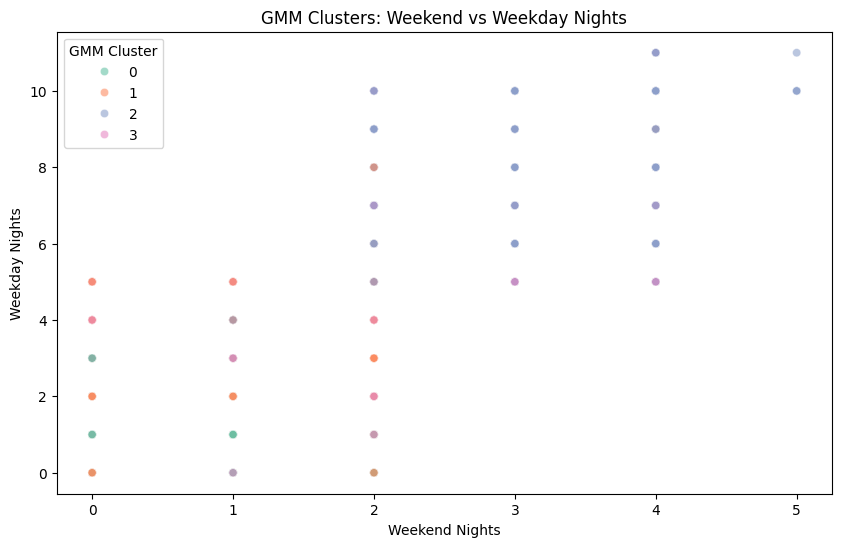

,count
gmm_cluster,
0,1307
1,2269
2,1488
3,950


In [14]:
gmm = GaussianMixture(n_components=4, random_state=42)

gmm.fit(X_scaled)

gmm_probs = gmm.predict_proba(X_scaled)

df_cluster['gmm_cluster'] = gmm_probs.argmax(axis=1)

df_cluster.head()

gmm_prob_df = pd.DataFrame(
    gmm_probs,
    columns=['Cluster 0', 'Cluster 1', 'Cluster 2', 'Cluster 3'],
    index=df_cluster.index
)

gmm_prob_df.head()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x='lead_time',
    y='adr',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.6
)

plt.title('GMM Clusters: Lead Time vs ADR')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate')
plt.legend(title='GMM Cluster')
plt.show()


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x='stays_in_weekend_nights',
    y='stays_in_week_nights',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.6
)

plt.title('GMM Clusters: Weekend vs Weekday Nights')
plt.xlabel('Weekend Nights')
plt.ylabel('Weekday Nights')
plt.legend(title='GMM Cluster')
plt.show()

gmm_summary = df_cluster.groupby('gmm_cluster')[features].mean()

gmm_summary = gmm_summary.round(2)

gmm_summary


df_cluster['gmm_cluster'].value_counts().sort_index()


### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM results were similar to K-Means because both models divided customers into four groups based on their booking behavior. GMM seemed to separate customers more clearly based on lead time, especially those who booked further in advance. GMM also uses probabilities, which makes it more flexible when customers have characteristics that overlap between clusters.

2. I believe GMM could help hotels understand customers who don't fit perfectly into one group. For example, it could help identify guests who might respond to different promotions based on their booking habits, room rates, or length of stay. This could help hotels create more personalized marketing campaigns and better target customers.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [15]:
kmeans_wcss = kmeans.inertia_

gmm_labels = df_cluster['gmm_cluster'].to_numpy()

gmm_wcss = sum(
    np.sum((X_scaled.to_numpy()[gmm_labels == i] -
            X_scaled.to_numpy()[gmm_labels == i].mean(axis=0)) ** 2)
    for i in range(4)
    if np.any(gmm_labels == i)
)

kmeans_silhouette = silhouette_score(
    X_scaled, df_cluster['cluster'],
    sample_size=10000,
    random_state=42
)

gmm_silhouette = silhouette_score(
    X_scaled, df_cluster['gmm_cluster'],
    sample_size=10000,
    random_state=42
)

kmeans_db = davies_bouldin_score(
    X_scaled, df_cluster['cluster']
)

gmm_db = davies_bouldin_score(
    X_scaled, df_cluster['gmm_cluster']
)

evaluation = pd.DataFrame({
    'Model': ['K-Means', 'GMM'],
    'WCSS': [kmeans_wcss, gmm_wcss],
    'Silhouette Score': [kmeans_silhouette, gmm_silhouette],
    'Davies-Bouldin Index': [kmeans_db, gmm_db]
})

evaluation.round(3)


,Model,WCSS,Silhouette Score,Davies-Bouldin Index
0,K-Means,15686.623,0.241,1.395
1,GMM,18418.439,0.133,1.772


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better across all three evaluation metrics. It had a lower WCSS of 15,686.623 compared to GMM's 18,418.439, a higher Silhouette Score of 0.241 compared to 0.133, and a lower Davies-Bouldin Index of 1.395 compared to 1.772. This suggests that K-Means created tighter and more clearly separated clusters.

5.3.  I would recommend K-Means for a business analyst because it performed better on all three metrics and is easier to interpret. It would help hotels identify different customer groups and create targeted marketing campaigns. Although GMM is useful because it provides probabilities, I think K-Means would be a better choice for this dataset because its clusters were more clearly defined.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

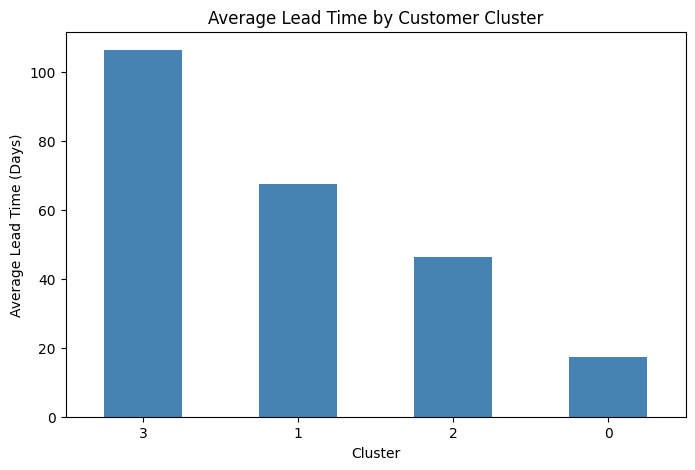

In [16]:
cluster_characteristics = df_cluster.groupby('cluster')[features].mean()

cluster_characteristics = cluster_characteristics.round(2)

cluster_characteristics

cluster_sorted = cluster_characteristics.sort_values(
    by='lead_time',
    ascending=False
)

cluster_sorted

cluster_sorted['lead_time'].plot(
    kind='bar',
    figsize=(8, 5),
    color='steelblue'
)

plt.title('Average Lead Time by Customer Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Lead Time (Days)')
plt.xticks(rotation=0)
plt.show()



### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The segments represent different types of customers based on how far in advance they book their hotel stays. Cluster 3 represents early planners who book around 106 days in advance, while Cluster 1 includes customers who book around 68 days ahead. Cluster 2 represents customers who book about 47 days in advance, and Cluster 0 includes last-minute bookers who book around 17 days before arrival.

2. The hotel could create different promotions for each group based on their booking habits. For Cluster 3, they could offer early booking discounts or vacation packages. Cluster 1 could receive seasonal promotions, while Cluster 2 could receive limited-time offers. For Cluster 0, the hotel could offer last-minute deals to fill empty rooms. This would help the hotel target customers more effectively and potentially increase bookings.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. I think the most challenging part of unsupervised learning was figuring out what each cluster actually represented. Unlike supervised learning, there are no predefined labels, so we had to look at the different variables and patterns to understand the customer groups. It was also interesting to see how K-Means and GMM produced different results using the same data.

2. I would use clustering when I want to find patterns in data without already knowing the categories. For example, a hotel could use clustering to group customers based on their booking habits. Supervised learning would be more useful if I wanted to predict something specific, like whether a customer would cancel their reservation.

3. I would explain clustering as a way for businesses to better understand their customers by grouping people with similar behaviors. Instead of sending the same promotions to everyone, hotels could use these groups to offer more personalized deals. This could help improve customer satisfaction, increase bookings, and make marketing more effective.

4. This assignment relates to my interest in finance and wealth management because customer segmentation can also be used in financial services. Financial advisors could group clients based on their investment preferences, financial goals, or risk tolerance. This would help them better understand their clients and provide more personalized financial recommendations.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [17]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_09_clustering.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
